### 1. Load and Prepare the Dataset
We will use the Breast Cancer Wisconsin dataset from `sklearn.datasets`. This is a classic binary supervised classification dataset.

In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(f"Dataset shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True)}")

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

display(X.head())

Dataset shape: (569, 30)
Target distribution:
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 2. Define, Train, and Evaluate Models
We will train the following models:
*   **Bagging:** `BaggingClassifier` (with Decision Trees) and `RandomForestClassifier`
*   **Boosting:** `AdaBoostClassifier` and `GradientBoostingClassifier`

In [3]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize models
models = {
    'Bagging (Decision Trees)': BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42, algorithm='SAMME'),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Evaluate and store results
results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba)
    })

# Convert to DataFrame for comparison
df_results = pd.DataFrame(results)
display(df_results.style.highlight_max(color='lightgreen', subset=df_results.columns[1:]))

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Bagging (Decision Trees),0.938596,0.945205,0.958333,0.951724,0.992725
1,Random Forest,0.956140,0.958904,0.972222,0.965517,0.993882
2,AdaBoost,0.956140,0.946667,0.986111,0.965986,0.981812
3,Gradient Boosting,0.956140,0.946667,0.986111,0.965986,0.990741


### 3. Visualize Model Comparison

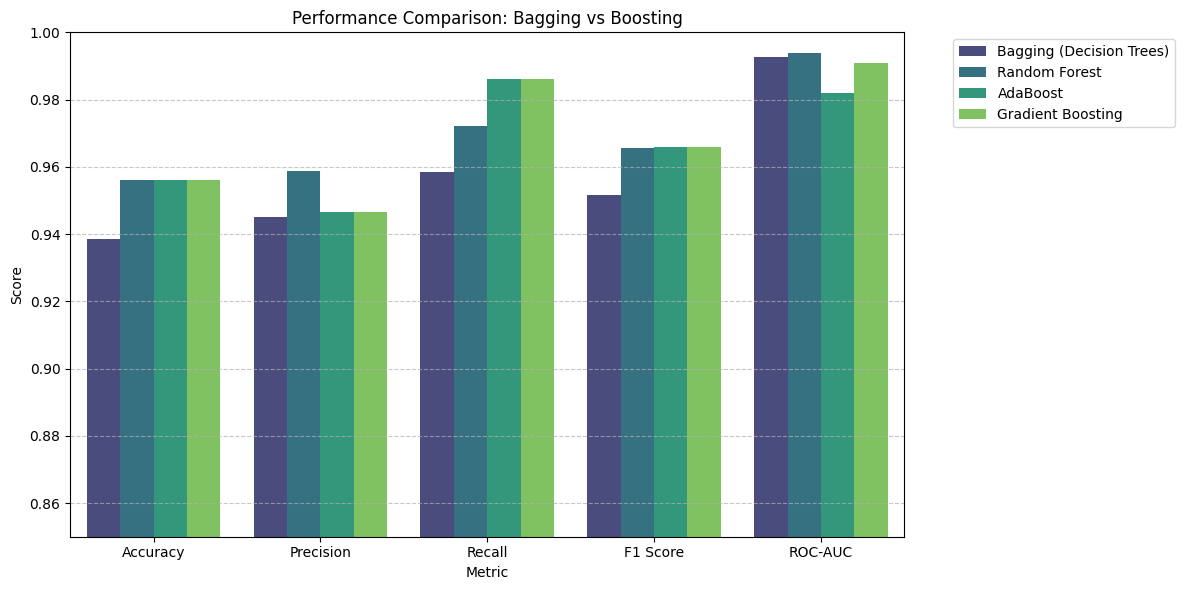

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

df_melted = df_results.melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x='Metric', y='Value', hue='Model', palette='viridis')
plt.title('Performance Comparison: Bagging vs Boosting')
plt.ylim(0.85, 1.0) # Zoom in to highlight small performance variations
plt.ylabel('Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()